In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data=pd.read_csv('website_Data.csv')
data

,Page Views,Session Duration,Bounce Rate,Traffic Source,Time on Page,Previous Visits,Conversion Rate
0,5,11.051381,0.230652,Organic,3.890460,3,1.0
1,4,3.429316,0.391001,Social,8.478174,0,1.0
2,4,1.621052,0.397986,Organic,9.636170,2,1.0
3,5,3.629279,0.180458,Organic,2.071925,3,1.0
4,5,4.235843,0.291541,Paid,1.960654,5,1.0
...,...,...,...,...,...,...,...
1995,1,2.724513,0.207187,Referral,1.324206,2,1.0
1996,3,0.392856,0.095559,Organic,3.824416,1,1.0
1997,4,9.899823,0.446622,Organic,1.288675,1,1.0
1998,3,0.393319,0.278340,Paid,5.037584,2,1.0


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Page Views        2000 non-null   int64  
 1   Session Duration  2000 non-null   float64
 2   Bounce Rate       2000 non-null   float64
 3   Traffic Source    2000 non-null   str    
 4   Time on Page      2000 non-null   float64
 5   Previous Visits   2000 non-null   int64  
 6   Conversion Rate   2000 non-null   float64
dtypes: float64(4), int64(2), str(1)
memory usage: 109.5 KB


In [4]:
data.describe()

,Page Views,Session Duration,Bounce Rate,Time on Page,Previous Visits,Conversion Rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,4.950500,3.022045,0.284767,4.027439,1.978500,0.982065
std,2.183903,3.104518,0.159781,2.887422,1.432852,0.065680
min,0.000000,0.003613,0.007868,0.068515,0.000000,0.343665
25%,3.000000,0.815828,0.161986,1.935037,1.000000,1.000000
50%,5.000000,1.993983,0.266375,3.315316,2.000000,1.000000
75%,6.000000,4.197569,0.388551,5.414627,3.000000,1.000000
max,14.000000,20.290516,0.844939,24.796182,9.000000,1.000000


In [5]:
data.isnull().sum()

Page Views          0
Session Duration    0
Bounce Rate         0
Traffic Source      0
Time on Page        0
Previous Visits     0
Conversion Rate     0
dtype: int64

In [6]:
data.columns

Index(['Page Views', 'Session Duration', 'Bounce Rate', 'Traffic Source',
       'Time on Page', 'Previous Visits', 'Conversion Rate'],
      dtype='str')

In [7]:
data["Traffic Source"].value_counts()

Traffic Source
Organic     786
Paid        428
Referral    301
Social      269
Direct      216
Name: count, dtype: int64

In [8]:
data.groupby("Traffic Source")["Conversion Rate"].mean()

Traffic Source
Direct      0.978679
Organic     0.982282
Paid        0.979009
Referral    0.987727
Social      0.982679
Name: Conversion Rate, dtype: float64

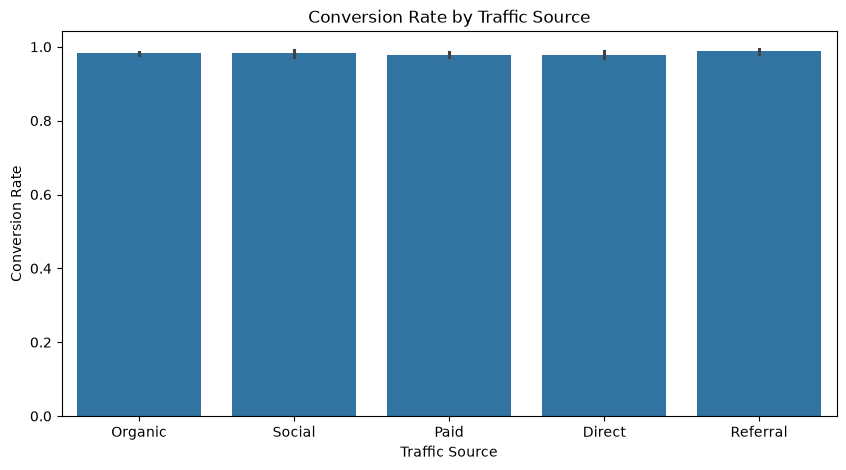

In [9]:
plt.figure(figsize=(10,5))
sns.barplot(x=data["Traffic Source"], y=data["Conversion Rate"])
plt.title("Conversion Rate by Traffic Source")
plt.show()

In [10]:
data.groupby("Conversion Rate")[["Session Duration", "Page Views", "Time on Page"]].mean()

,Session Duration,Page Views,Time on Page
Conversion Rate,,,
0.343665,0.432437,4.000000,1.398358
0.402910,0.870092,0.000000,0.266102
0.468486,0.453597,5.000000,0.327199
0.506747,1.805000,2.000000,0.742666
0.508227,0.242485,3.000000,1.722425
...,...,...,...
0.997645,1.273818,1.000000,3.399025
0.997793,0.169563,4.000000,3.041127
0.998369,4.345933,1.000000,2.452760


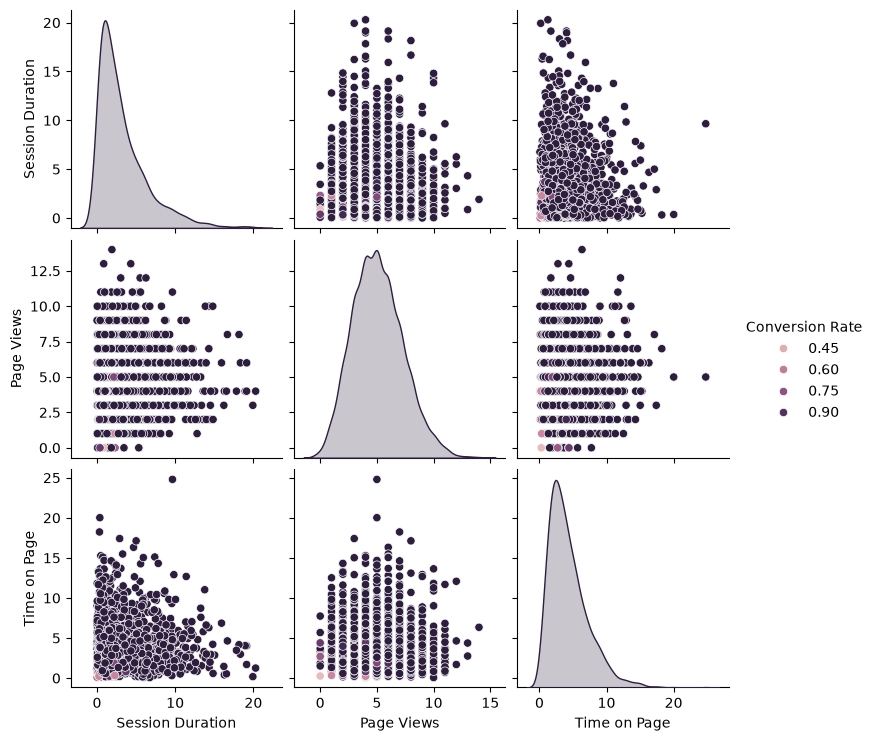

In [11]:
sns.pairplot(data, vars=["Session Duration", "Page Views", "Time on Page"], hue="Conversion Rate")
plt.show()

In [12]:
data["Bounce Rate"] = data["Bounce Rate"] / 100
data["Bounce Rate"] = data["Bounce Rate"].round(2)
data["Bounce Rate"].head()

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: Bounce Rate, dtype: float64

In [13]:
data.groupby("Traffic Source")["Bounce Rate"].mean().sort_values(ascending=False)

Traffic Source
Social      0.001264
Paid        0.001192
Organic     0.001170
Direct      0.000787
Referral    0.000698
Name: Bounce Rate, dtype: float64

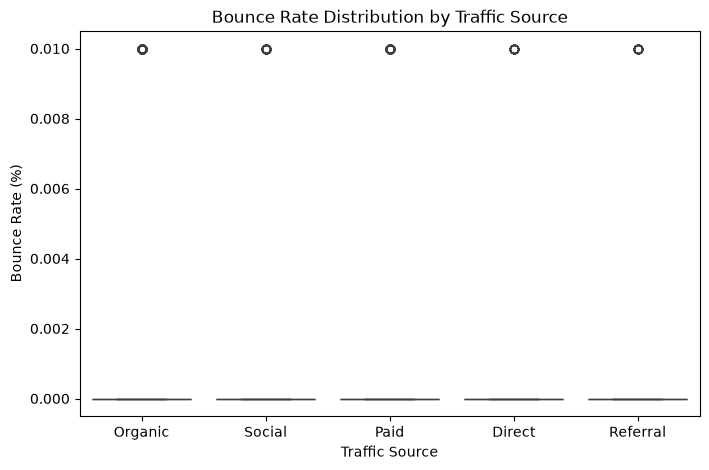

In [14]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Traffic Source", y="Bounce Rate", data=data)
plt.title("Bounce Rate Distribution by Traffic Source")
plt.ylabel("Bounce Rate (%)")
plt.show()

In [15]:
selected_columns = ["Page Views", "Session Duration", "Bounce Rate", "Conversion Rate", "Time on Page"]
numeric_data = data[selected_columns]

correlation_matrix = numeric_data.corr()
print(correlation_matrix)

                  Page Views  Session Duration  Bounce Rate  Conversion Rate  \
Page Views          1.000000         -0.012788     0.036702         0.126635   
Session Duration   -0.012788          1.000000    -0.014258         0.177798   
Bounce Rate         0.036702         -0.014258     1.000000        -0.027653   
Conversion Rate     0.126635          0.177798    -0.027653         1.000000   
Time on Page        0.023941         -0.013985     0.013620         0.229669   

                  Time on Page  
Page Views            0.023941  
Session Duration     -0.013985  
Bounce Rate           0.013620  
Conversion Rate       0.229669  
Time on Page          1.000000  


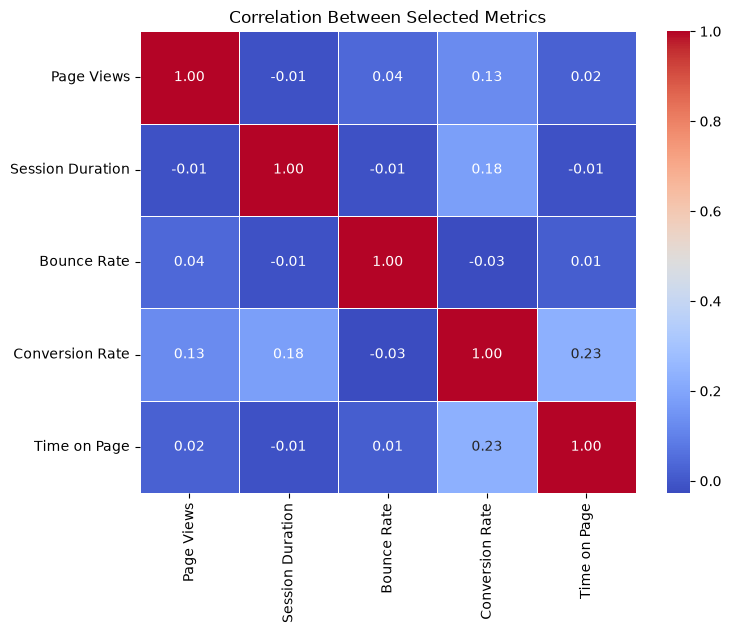

In [16]:
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Between Selected Metrics")
plt.show()